<a href="https://colab.research.google.com/github/SAMBOAH95/Machine-Learning-Projects/blob/main/Level%203/Task%206/Music_Genre_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# Install required libraries
!pip install -q librosa scikit-learn matplotlib seaborn pandas numpy kagglehub

# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Libraries installed and imported successfully!")
print("Librosa version:", librosa.__version__)


Libraries installed and imported successfully!
Librosa version: 0.11.0


In [3]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Set the existing project directory
project_path = "/content/drive/MyDrive/Elevo/Level 3/Task 6"

# Verify that the folder exists
if os.path.exists(project_path):
    print("Project folder found successfully!")
    print("Location:", project_path)
else:
    print("Folder not found. Please check the path.")

Project folder found successfully!
Location: /content/drive/MyDrive/Elevo/Level 3/Task 6


In [5]:
import kagglehub
import shutil

# Download GTZAN dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)

print("Dataset downloaded successfully!")
print("Original dataset location:", dataset_path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Dataset downloaded successfully!
Original dataset location: /kaggle/input/gtzan-dataset-music-genre-classification


In [6]:
# Explore the downloaded dataset
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        indent = " " * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

        if len(files) > 5:
            print(f"{indent}    ... and {len(files) - 5} more files")

gtzan-dataset-music-genre-classification/
    Data/
        features_3_sec.csv
        features_30_sec.csv
        images_original/
        genres_original/


In [7]:
# Locate the feature dataset
data_path = os.path.join(dataset_path, "Data")

features_file = os.path.join(data_path, "features_3_sec.csv")

# Load the dataset
df = pd.read_csv(features_file)

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (9990, 60)

First five rows:


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues



Column names:
['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean', 'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var', 'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean', 'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var', 'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean', 'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var', 'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean', 'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var', 'label']


Total missing values: 0
Duplicate rows: 0

Number of samples per genre:
label
blues        1000
classical     998
country       997
disco         999
hiphop        998
jazz         1000
metal        1000
pop          1000
reggae       1000
rock          998
Name: count, dtype: int64


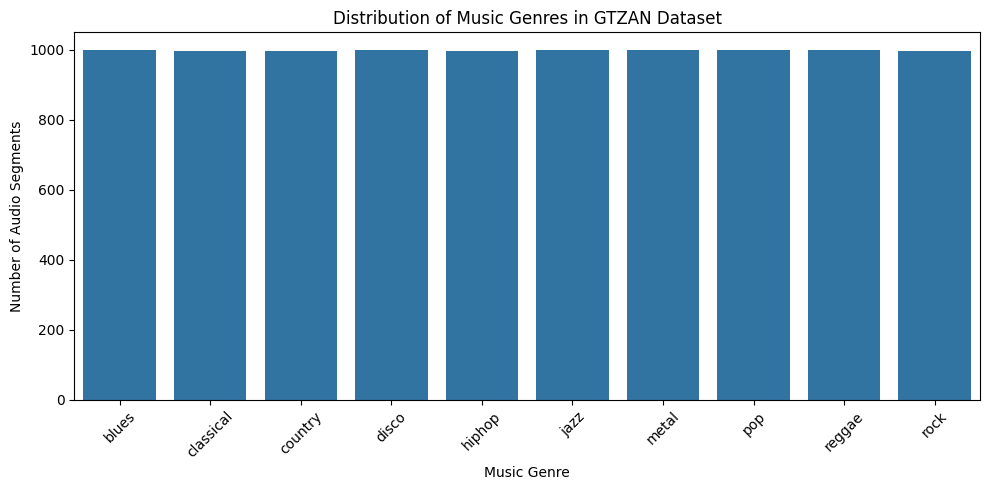

In [8]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Count samples in each genre
print("\nNumber of samples per genre:")
print(df["label"].value_counts().sort_index())

# Visualise genre distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="label", order=sorted(df["label"].unique()))

plt.title("Distribution of Music Genres in GTZAN Dataset")
plt.xlabel("Music Genre")
plt.ylabel("Number of Audio Segments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Separate input features and target variable
X = df.drop(columns=["filename", "length", "label"])
y = df["label"]

# Check the resulting datasets
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique()))

print("\nFirst five feature records:")
display(X.head())

Feature matrix shape: (9990, 57)
Target variable shape: (9990,)

Target classes:
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

First five feature records:


,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,1.080790e+06,...,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767
1,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,6.722448e+05,...,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081
2,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,7.907127e+05,...,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122
3,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,9.216524e+05,...,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678
4,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,6.102111e+05,...,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694


In [10]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining genre distribution:")
print(y_train.value_counts().sort_index())

Training features: (7992, 57)
Testing features: (1998, 57)

Training labels: (7992,)
Testing labels: (1998,)

Training genre distribution:
label
blues        800
classical    799
country      798
disco        799
hiphop       798
jazz         800
metal        800
pop          800
reggae       800
rock         798
Name: count, dtype: int64


In [11]:

import shutil

# Define destination folder in Google Drive
drive_dataset_path = os.path.join(project_path, "GTZAN_Dataset")

# Copy the downloaded dataset into Google Drive
if not os.path.exists(drive_dataset_path):
    shutil.copytree(dataset_path, drive_dataset_path)
    print("GTZAN dataset successfully saved to Google Drive!")
else:
    print("GTZAN dataset already exists in Google Drive.")

print("Dataset location:", drive_dataset_path)


GTZAN dataset already exists in Google Drive.
Dataset location: /content/drive/MyDrive/Elevo/Level 3/Task 6/GTZAN_Dataset


In [12]:
from sklearn.preprocessing import StandardScaler

# Initialise the scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature standardisation completed!")
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

print("\nTraining feature means (first 5):")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining feature standard deviations (first 5):")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

Feature standardisation completed!
Scaled training data: (7992, 57)
Scaled testing data: (1998, 57)

Training feature means (first 5):
[-0. -0. -0. -0.  0.]

Training feature standard deviations (first 5):
[1. 1. 1. 1. 1.]


In [13]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialise Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_scaled)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Model Training Completed!")
print(f"\nAccuracy: {rf_accuracy:.4f}")
print(f"Accuracy Percentage: {rf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Model Training Completed!

Accuracy: 0.8709
Accuracy Percentage: 87.09%

Classification Report:
              precision    recall  f1-score   support

       blues       0.87      0.86      0.87       200
   classical       0.90      0.95      0.93       199
     country       0.80      0.83      0.82       199
       disco       0.85      0.84      0.85       200
      hiphop       0.92      0.90      0.91       200
        jazz       0.85      0.90      0.87       200
       metal       0.87      0.97      0.92       200
         pop       0.95      0.81      0.88       200
      reggae       0.82      0.88      0.85       200
        rock       0.89      0.76      0.82       200

    accuracy                           0.87      1998
   macro avg       0.87      0.87      0.87      1998
weighted avg       0.87      0.87      0.87      1998



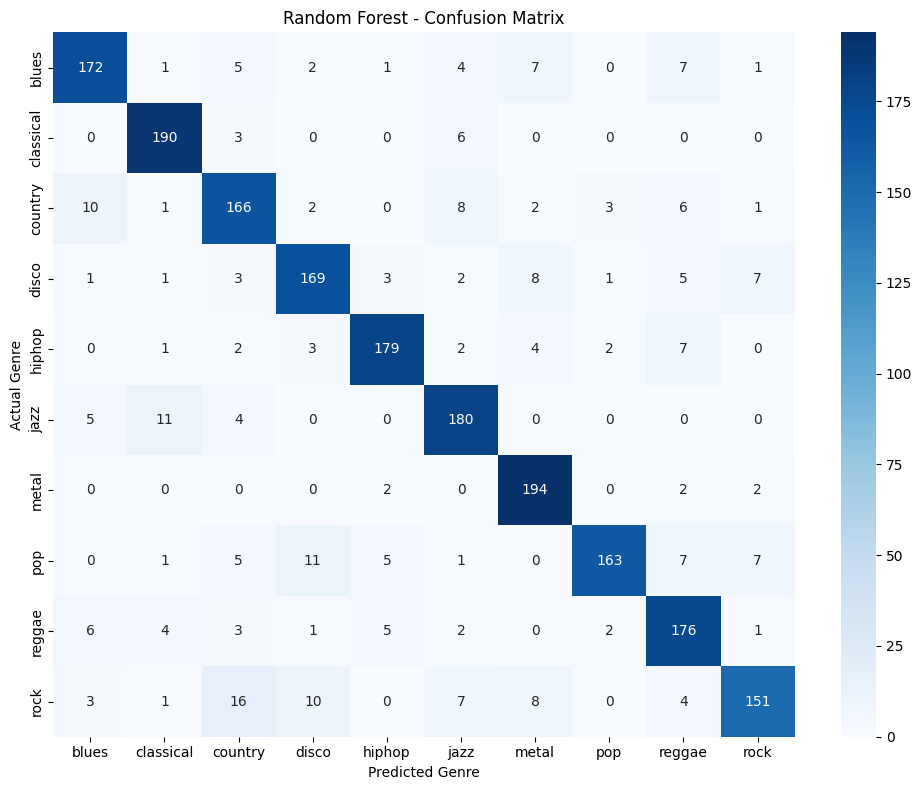

In [14]:

# Generate confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=rf_model.classes_
)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Initialise SVM model
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_scaled)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Model Training Completed!")
print(f"\nAccuracy: {svm_accuracy:.4f}")
print(f"Accuracy Percentage: {svm_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

SVM Model Training Completed!

Accuracy: 0.9134
Accuracy Percentage: 91.34%

Classification Report:
              precision    recall  f1-score   support

       blues       0.90      0.94      0.92       200
   classical       0.92      0.98      0.95       199
     country       0.87      0.86      0.87       199
       disco       0.88      0.88      0.88       200
      hiphop       0.93      0.91      0.92       200
        jazz       0.92      0.94      0.93       200
       metal       0.98      0.95      0.97       200
         pop       0.94      0.86      0.90       200
      reggae       0.90      0.92      0.91       200
        rock       0.90      0.90      0.90       200

    accuracy                           0.91      1998
   macro avg       0.91      0.91      0.91      1998
weighted avg       0.91      0.91      0.91      1998



MODEL PERFORMANCE COMPARISON


,Model,Accuracy
0,Random Forest,0.870871
1,SVM,0.913413


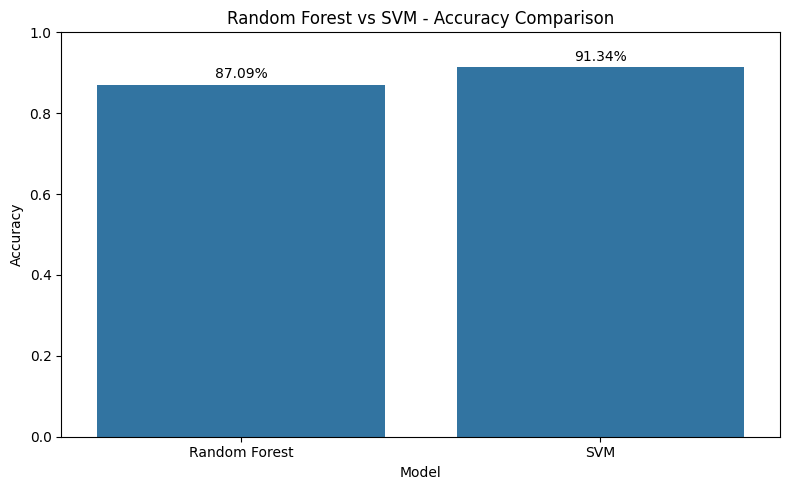

In [16]:

# Compare model performance
model_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM"],
    "Accuracy": [rf_accuracy, svm_accuracy]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_results)

# Visualise accuracy
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="Accuracy"
)

plt.title("Random Forest vs SVM - Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_results["Accuracy"]):
    plt.text(i, value + 0.015, f"{value:.2%}", ha="center")

plt.tight_layout()
plt.show()

In [17]:
# Define spectrogram image directory
images_path = os.path.join(data_path, "images_original")

# List genre folders
genres = sorted([
    folder for folder in os.listdir(images_path)
    if os.path.isdir(os.path.join(images_path, folder))
])

print("Number of genres:", len(genres))
print("\nGenre folders:")
print(genres)

# Count images in each genre
print("\nImages per genre:")

for genre in genres:
    genre_path = os.path.join(images_path, genre)
    image_files = [
        f for f in os.listdir(genre_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    print(f"{genre}: {len(image_files)}")

Number of genres: 10

Genre folders:
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

Images per genre:
blues: 100
classical: 100
country: 100
disco: 100
hiphop: 100
jazz: 99
metal: 100
pop: 100
reggae: 100
rock: 100


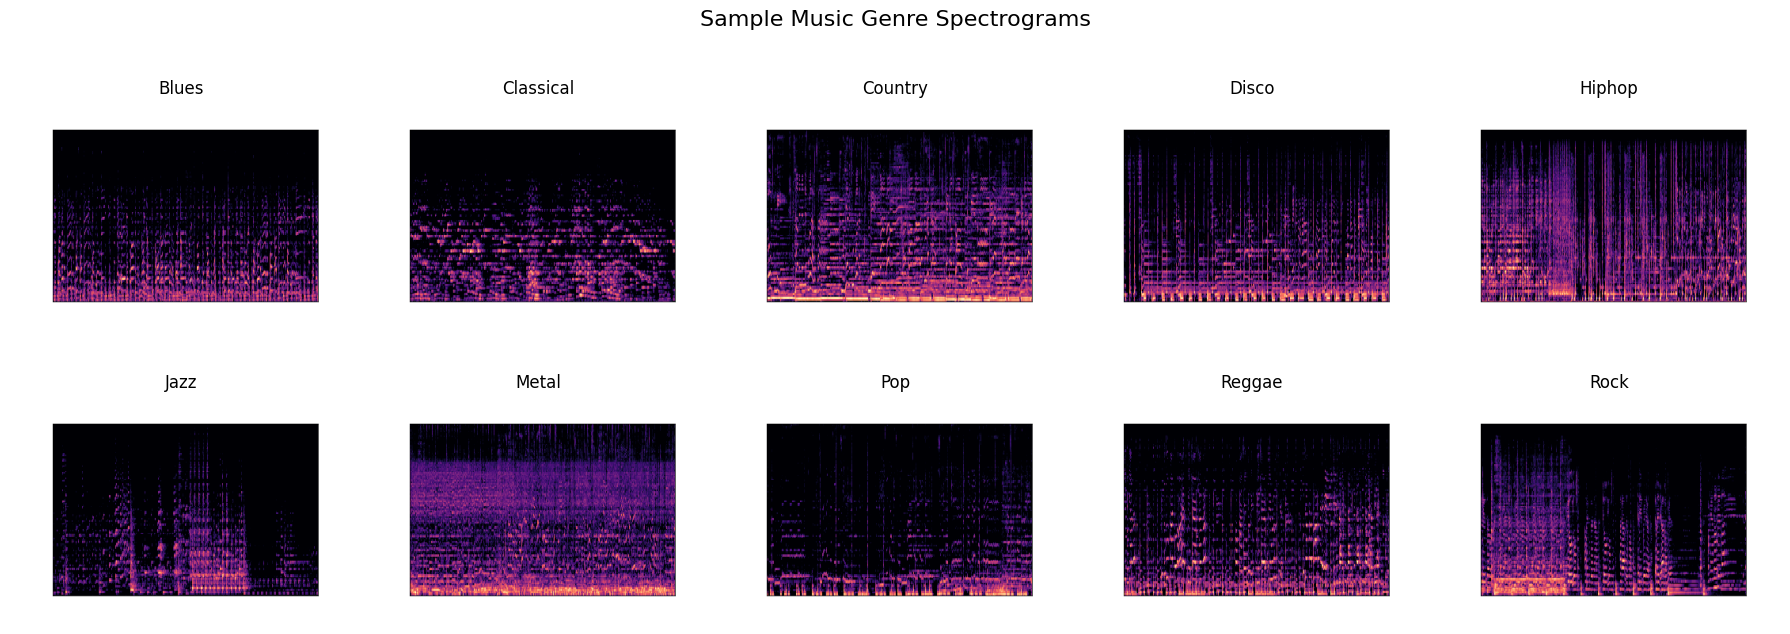

In [18]:

from PIL import Image

# Display one spectrogram from each genre
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, genre in enumerate(genres):
    genre_path = os.path.join(images_path, genre)

    image_files = sorted([
        f for f in os.listdir(genre_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    image_path = os.path.join(genre_path, image_files[0])

    img = Image.open(image_path)

    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(genre.capitalize())
    ax.axis("off")

plt.suptitle("Sample Music Genre Spectrograms", fontsize=16)
plt.tight_layout()
plt.show()

In [19]:

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [20]:

from tensorflow.keras.utils import load_img, img_to_array
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm

# Image settings
IMG_SIZE = (128, 128)

images = []
labels = []

# Load images from each genre folder
for genre in genres:
    genre_path = os.path.join(images_path, genre)

    image_files = sorted([
        f for f in os.listdir(genre_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    for file in tqdm(image_files, desc=f"Loading {genre}"):
        image_path = os.path.join(genre_path, file)

        img = load_img(image_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)

        images.append(img_array)
        labels.append(genre)

# Convert to NumPy arrays
X_images = np.array(images, dtype="float32") / 255.0
y_images = np.array(labels)

# Encode genre labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_images)

print("\nImage loading completed!")
print("Image dataset shape:", X_images.shape)
print("Encoded labels shape:", y_encoded.shape)
print("Genres:", label_encoder.classes_)

Loading blues:   0%|          | 0/100 [00:00<?, ?it/s]

Loading classical:   0%|          | 0/100 [00:00<?, ?it/s]

Loading country:   0%|          | 0/100 [00:00<?, ?it/s]

Loading disco:   0%|          | 0/100 [00:00<?, ?it/s]

Loading hiphop:   0%|          | 0/100 [00:00<?, ?it/s]

Loading jazz:   0%|          | 0/99 [00:00<?, ?it/s]

Loading metal:   0%|          | 0/100 [00:00<?, ?it/s]

Loading pop:   0%|          | 0/100 [00:00<?, ?it/s]

Loading reggae:   0%|          | 0/100 [00:00<?, ?it/s]

Loading rock:   0%|          | 0/100 [00:00<?, ?it/s]


Image loading completed!
Image dataset shape: (999, 128, 128, 3)
Encoded labels shape: (999,)
Genres: ['blues' 'classical' 'country' 'disco' 'hiphop' 'jazz' 'metal' 'pop'
 'reggae' 'rock']


In [21]:
# Split image dataset
X_img_train, X_img_test, y_img_train, y_img_test = train_test_split(
    X_images,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("CNN Training images:", X_img_train.shape)
print("CNN Testing images:", X_img_test.shape)

print("\nTraining labels:", y_img_train.shape)
print("Testing labels:", y_img_test.shape)

print("\nTraining distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_img_train)
).value_counts().sort_index())

CNN Training images: (799, 128, 128, 3)
CNN Testing images: (200, 128, 128, 3)

Training labels: (799,)
Testing labels: (200,)

Training distribution:
blues        80
classical    80
country      80
disco        80
hiphop       80
jazz         79
metal        80
pop          80
reggae       80
rock         80
Name: count, dtype: int64


In [22]:
from tensorflow.keras import layers, models

# Build CNN architecture
cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Ten genre classes
    layers.Dense(10, activation="softmax")
])

# Compile model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:

# Train CNN model
history = cnn_model.fit(
    X_img_train,
    y_img_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.1095 - loss: 2.3233 - val_accuracy: 0.1625 - val_loss: 2.2371
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.1862 - loss: 2.1984 - val_accuracy: 0.2188 - val_loss: 2.1086
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2473 - loss: 2.0491 - val_accuracy: 0.3250 - val_loss: 1.9787
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.2989 - loss: 1.9428 - val_accuracy: 0.4000 - val_loss: 1.8555
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.3459 - loss: 1.8335 - val_accuracy: 0.3313 - val_loss: 1.7813
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.3693 - loss: 1.7217 - val_accuracy: 0.4125 - val_loss: 1.6634
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.4476 - loss: 1.5802 - val_accuracy: 0.4437 - val_loss: 1.6089
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4930 - loss: 1.4763 - val_accuracy: 0.5063 - val_loss:

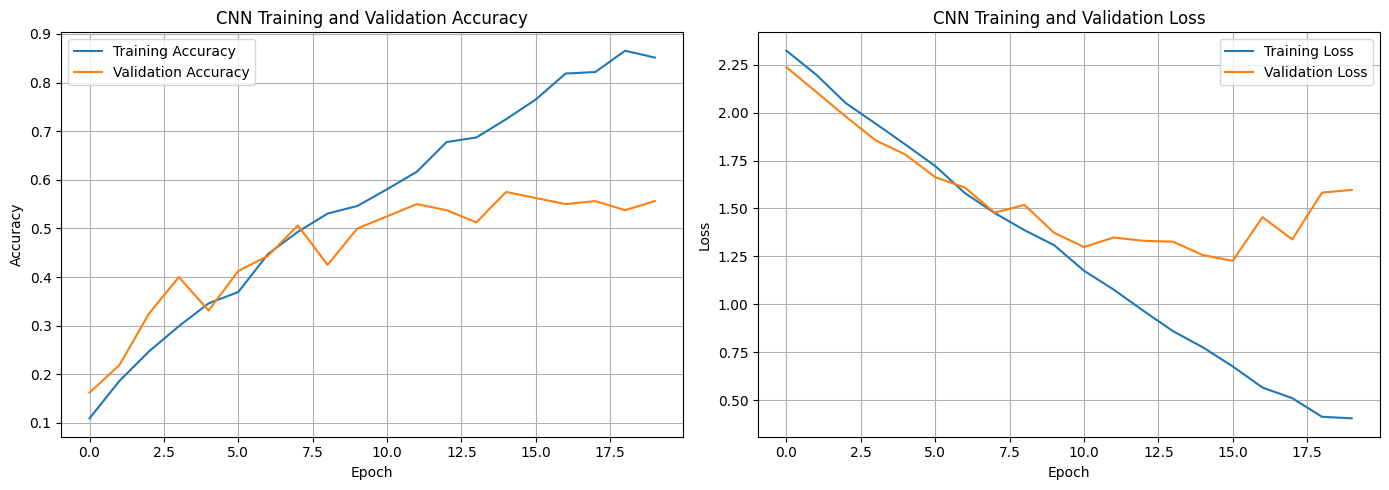

In [24]:

# Plot CNN training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [25]:

# Evaluate CNN on test data
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_img_test,
    y_img_test,
    verbose=1
)

print("\nCNN Test Results")
print(f"Test Loss: {cnn_loss:.4f}")
print(f"Test Accuracy: {cnn_accuracy:.4f}")
print(f"Test Accuracy Percentage: {cnn_accuracy * 100:.2f}%")

# Generate predictions
cnn_probabilities = cnn_model.predict(X_img_test)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

# Classification report
print("\nCNN Classification Report:")
print(classification_report(
    y_img_test,
    cnn_predictions,
    target_names=label_encoder.classes_
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 232ms/step - accuracy: 0.5650 - loss: 1.7112

CNN Test Results
Test Loss: 1.7112
Test Accuracy: 0.5650
Test Accuracy Percentage: 56.50%
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 233ms/step

CNN Classification Report:
              precision    recall  f1-score   support

       blues       0.45      0.25      0.32        20
   classical       0.89      0.85      0.87        20
     country       0.42      0.65      0.51        20
       disco       0.53      0.45      0.49        20
      hiphop       0.44      0.70      0.54        20
        jazz       0.62      0.75      0.68        20
       metal       0.80      0.60      0.69        20
         pop       0.64      0.80      0.71        20
      reggae       0.67      0.30      0.41        20
        rock       0.35      0.30      0.32        20

    accuracy                           0.56       200
   macro avg       0.58      0.56      0.55       200
weighted avg       0.58      0.56      0.55       200



In [26]:

from tensorflow.keras import layers, models, regularizers

# Build improved CNN with data augmentation
improved_cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu",
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu",
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

improved_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

# Train improved CNN
improved_history = improved_cnn.fit(
    X_img_train,
    y_img_train,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.0986 - loss: 2.3495 - val_accuracy: 0.0812 - val_loss: 2.3366 - learning_rate: 0.0010
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.1424 - loss: 2.3240 - val_accuracy: 0.1375 - val_loss: 2.3129 - learning_rate: 0.0010
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.1628 - loss: 2.2820 - val_accuracy: 0.1437 - val_loss: 2.2597 - learning_rate: 0.0010
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.1925 - loss: 2.2136 - val_accuracy: 0.1187 - val_loss: 2.3471 - learning_rate: 0.0010
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.1768 - loss: 2.1777 - val_accuracy: 0.1750 - val_loss: 2.1952 - learning_rate: 0.0010
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.2113 - loss: 2.1381 - val_accuracy: 0.1625 - val_loss: 2.2401 - learning_rate: 0.0010
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2081 - loss: 2.1323 - val_accuracy: 

In [28]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

# Train improved CNN
improved_history = improved_cnn.fit(
    X_img_train,
    y_img_train,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.2003 - loss: 2.0997 - val_accuracy: 0.1875 - val_loss: 2.1865 - learning_rate: 2.5000e-04
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.2066 - loss: 2.1010 - val_accuracy: 0.1750 - val_loss: 2.1700 - learning_rate: 2.5000e-04
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.2207 - loss: 2.0607 - val_accuracy: 0.1875 - val_loss: 2.1795 - learning_rate: 2.5000e-04
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.2019 - loss: 2.0657 - val_accuracy: 0.1875 - val_loss: 2.1487 - learning_rate: 2.5000e-04
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.2300 - loss: 2.0564 - val_accuracy: 0.1813 - val_loss: 2.1920 - learning_rate: 2.5000e-04
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2113 - loss: 2.0758 - val_accuracy: 0.1688 - val_loss: 2.2030 - learning_rate: 2.5000e-04
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2300 - loss:

In [29]:

# Build a smaller CNN without geometric augmentation
cnn_v3 = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

cnn_v3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Version 3 created successfully!")
cnn_v3.summary()


CNN Version 3 created successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:

# Define early stopping
early_stop_v3 = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

# Train CNN Version 3
history_v3 = cnn_v3.fit(
    X_img_train,
    y_img_train,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop_v3],
    verbose=1
)


Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.0939 - loss: 2.3059 - val_accuracy: 0.1375 - val_loss: 2.2999
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.1315 - loss: 2.2849 - val_accuracy: 0.1312 - val_loss: 2.2620
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.1737 - loss: 2.2305 - val_accuracy: 0.2125 - val_loss: 2.1854
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.1894 - loss: 2.1450 - val_accuracy: 0.2000 - val_loss: 2.1517
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.2003 - loss: 2.1186 - val_accuracy: 0.1312 - val_loss: 2.1447
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.2175 - loss: 2.0716 - val_accuracy: 0.1937 - val_loss: 2.0754
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2175 - loss: 2.0233 - val_accuracy: 0.2375 - val_loss: 2.0470
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.2410 - loss: 1.9933 - val_accuracy: 0.2375 - val_loss:

In [31]:

# Evaluate CNN Version 3
cnn_v3_loss, cnn_v3_accuracy = cnn_v3.evaluate(
    X_img_test,
    y_img_test,
    verbose=1
)

print("\nCNN Version 3 Test Results")
print(f"Test Loss: {cnn_v3_loss:.4f}")
print(f"Test Accuracy: {cnn_v3_accuracy:.4f}")
print(f"Test Accuracy Percentage: {cnn_v3_accuracy * 100:.2f}%")

# Generate predictions
cnn_v3_probabilities = cnn_v3.predict(X_img_test)
cnn_v3_predictions = np.argmax(cnn_v3_probabilities, axis=1)

# Classification report
print("\nCNN Version 3 Classification Report:")
print(classification_report(
    y_img_test,
    cnn_v3_predictions,
    target_names=label_encoder.classes_
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - accuracy: 0.4650 - loss: 1.4628

CNN Version 3 Test Results
Test Loss: 1.4628
Test Accuracy: 0.4650
Test Accuracy Percentage: 46.50%
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 230ms/step

CNN Version 3 Classification Report:
              precision    recall  f1-score   support

       blues       0.50      0.20      0.29        20
   classical       0.77      0.85      0.81        20
     country       0.43      0.65      0.52        20
       disco       0.39      0.35      0.37        20
      hiphop       0.53      0.40      0.46        20
        jazz       0.48      0.75      0.59        20
       metal       0.79      0.55      0.65        20
         pop       0.00      0.00      0.00        20
      reggae       0.30      0.65      0.41        20
        rock       0.31      0.25      0.28        20

    accuracy                           0.47       200
   macro avg       0.45      0.47      0.44       200
weighted avg       0.45      0.47      0.44  

<Figure size 1000x800 with 0 Axes>

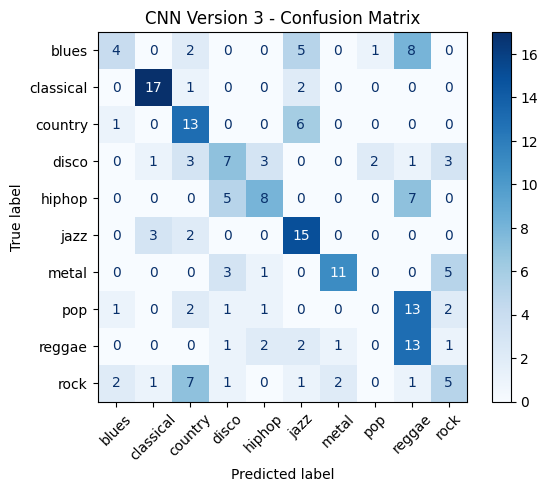

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm_v3 = confusion_matrix(y_img_test, cnn_v3_predictions)

# Display confusion matrix
plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_v3,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("CNN Version 3 - Confusion Matrix")
plt.show()

In [33]:
# Inspect feature filenames
print("First 20 feature filenames:")
display(df[["filename", "label"]].head(20))

# Count unique original tracks
print("\nTotal feature segments:", len(df))
print("Unique filenames:", df["filename"].nunique())

# Inspect image filenames
import os

images_path = os.path.join(data_path, "images_original")

for genre in sorted(os.listdir(images_path)):
    genre_path = os.path.join(images_path, genre)

    if os.path.isdir(genre_path):
        files = sorted(os.listdir(genre_path))
        print(f"\n{genre}:")
        print(files[:5])

First 20 feature filenames:


,filename,label
0,blues.00000.0.wav,blues
1,blues.00000.1.wav,blues
2,blues.00000.2.wav,blues
3,blues.00000.3.wav,blues
4,blues.00000.4.wav,blues
5,blues.00000.5.wav,blues
6,blues.00000.6.wav,blues
7,blues.00000.7.wav,blues
8,blues.00000.8.wav,blues
9,blues.00000.9.wav,blues



Total feature segments: 9990
Unique filenames: 9990

blues:
['blues00000.png', 'blues00001.png', 'blues00002.png', 'blues00003.png', 'blues00004.png']

classical:
['classical00000.png', 'classical00001.png', 'classical00002.png', 'classical00003.png', 'classical00004.png']

country:
['country00000.png', 'country00001.png', 'country00002.png', 'country00003.png', 'country00004.png']

disco:
['disco00000.png', 'disco00001.png', 'disco00002.png', 'disco00003.png', 'disco00004.png']

hiphop:
['hiphop00000.png', 'hiphop00001.png', 'hiphop00002.png', 'hiphop00003.png', 'hiphop00004.png']

jazz:
['jazz00000.png', 'jazz00001.png', 'jazz00002.png', 'jazz00003.png', 'jazz00004.png']

metal:
['metal00000.png', 'metal00001.png', 'metal00002.png', 'metal00003.png', 'metal00004.png']

pop:
['pop00000.png', 'pop00001.png', 'pop00002.png', 'pop00003.png', 'pop00004.png']

reggae:
['reggae00000.png', 'reggae00001.png', 'reggae00002.png', 'reggae00003.png', 'reggae00004.png']

rock:
['rock00000.png', '

In [34]:
# Extract original track ID from each filename
df["track_id"] = df["filename"].apply(
    lambda x: ".".join(x.split(".")[:2])
)

# Examine the grouping
print("Total feature segments:", len(df))
print("Unique original tracks:", df["track_id"].nunique())

# Check the number of segments per track
segments_per_track = df.groupby("track_id").size()

print("\nSegments per original track:")
print(segments_per_track.describe())

# Display sample track groups
print("\nSample track groups:")
display(
    df[["filename", "track_id", "label"]].head(15)
)

# Check whether every track has one genre
genre_counts_per_track = df.groupby("track_id")["label"].nunique()

print(
    "\nTracks associated with multiple genres:",
    (genre_counts_per_track > 1).sum()
)

Total feature segments: 9990
Unique original tracks: 1000

Segments per original track:
count    1000.000000
mean        9.990000
std         0.099549
min         9.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        10.000000
dtype: float64

Sample track groups:


,filename,track_id,label
0,blues.00000.0.wav,blues.00000,blues
1,blues.00000.1.wav,blues.00000,blues
2,blues.00000.2.wav,blues.00000,blues
3,blues.00000.3.wav,blues.00000,blues
4,blues.00000.4.wav,blues.00000,blues
5,blues.00000.5.wav,blues.00000,blues
6,blues.00000.6.wav,blues.00000,blues
7,blues.00000.7.wav,blues.00000,blues
8,blues.00000.8.wav,blues.00000,blues
9,blues.00000.9.wav,blues.00000,blues



Tracks associated with multiple genres: 0


In [35]:
from sklearn.model_selection import train_test_split

# Create a table containing one row per original track
track_data = df[["track_id", "label"]].drop_duplicates()

# Split original tracks, maintaining genre proportions
train_tracks, test_tracks = train_test_split(
    track_data,
    test_size=0.20,
    random_state=42,
    stratify=track_data["label"]
)

# Assign all segments belonging to each selected track
train_df = df[df["track_id"].isin(train_tracks["track_id"])].copy()
test_df = df[df["track_id"].isin(test_tracks["track_id"])].copy()

# Verify the split
print("Training tracks:", train_tracks.shape[0])
print("Testing tracks:", test_tracks.shape[0])

print("\nTraining segments:", train_df.shape[0])
print("Testing segments:", test_df.shape[0])

# Confirm no track leakage
overlap = set(train_df["track_id"]) & set(test_df["track_id"])

print("\nOverlapping tracks:", len(overlap))

# Check genre distribution
print("\nTraining genre distribution:")
print(train_tracks["label"].value_counts().sort_index())

print("\nTesting genre distribution:")
print(test_tracks["label"].value_counts().sort_index())

Training tracks: 800
Testing tracks: 200

Training segments: 7990
Testing segments: 2000

Overlapping tracks: 0

Training genre distribution:
label
blues        80
classical    80
country      80
disco        80
hiphop       80
jazz         80
metal        80
pop          80
reggae       80
rock         80
Name: count, dtype: int64

Testing genre distribution:
label
blues        20
classical    20
country      20
disco        20
hiphop       20
jazz         20
metal        20
pop          20
reggae       20
rock         20
Name: count, dtype: int64


In [36]:
from sklearn.preprocessing import StandardScaler

# Separate input features and target labels
X_train_grouped = train_df.drop(
    columns=["filename", "length", "label", "track_id"]
)

y_train_grouped = train_df["label"]

X_test_grouped = test_df.drop(
    columns=["filename", "length", "label", "track_id"]
)

y_test_grouped = test_df["label"]

# Standardise features using training data only
scaler_grouped = StandardScaler()

X_train_grouped_scaled = scaler_grouped.fit_transform(
    X_train_grouped
)

X_test_grouped_scaled = scaler_grouped.transform(
    X_test_grouped
)

# Verify dimensions
print("Training feature shape:", X_train_grouped_scaled.shape)
print("Testing feature shape:", X_test_grouped_scaled.shape)

print("\nTraining target shape:", y_train_grouped.shape)
print("Testing target shape:", y_test_grouped.shape)

print("\nTraining feature mean:", X_train_grouped_scaled.mean().round(4))
print("Training feature standard deviation:",
      X_train_grouped_scaled.std().round(4))

Training feature shape: (7990, 57)
Testing feature shape: (2000, 57)

Training target shape: (7990,)
Testing target shape: (2000,)

Training feature mean: -0.0
Training feature standard deviation: 1.0


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialise Random Forest
rf_grouped = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_grouped.fit(X_train_grouped, y_train_grouped)

# Make predictions
rf_grouped_predictions = rf_grouped.predict(X_test_grouped)

# Evaluate model
rf_grouped_accuracy = accuracy_score(
    y_test_grouped,
    rf_grouped_predictions
)

print("Random Forest - Song-Level Evaluation")
print(f"Test Accuracy: {rf_grouped_accuracy:.4f}")
print(f"Test Accuracy Percentage: {rf_grouped_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test_grouped,
    rf_grouped_predictions
))

Random Forest - Song-Level Evaluation
Test Accuracy: 0.7155
Test Accuracy Percentage: 71.55%

Classification Report:
              precision    recall  f1-score   support

       blues       0.72      0.68      0.70       200
   classical       0.90      0.95      0.92       200
     country       0.70      0.73      0.72       200
       disco       0.65      0.53      0.58       200
      hiphop       0.62      0.69      0.65       200
        jazz       0.70      0.84      0.76       200
       metal       0.84      0.81      0.83       200
         pop       0.73      0.79      0.75       200
      reggae       0.62      0.61      0.62       200
        rock       0.65      0.52      0.58       200

    accuracy                           0.72      2000
   macro avg       0.71      0.72      0.71      2000
weighted avg       0.71      0.72      0.71      2000



In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Initialise SVM
svm_grouped = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

# Train SVM using scaled training features
svm_grouped.fit(
    X_train_grouped_scaled,
    y_train_grouped
)

# Make predictions
svm_grouped_predictions = svm_grouped.predict(
    X_test_grouped_scaled
)

# Evaluate
svm_grouped_accuracy = accuracy_score(
    y_test_grouped,
    svm_grouped_predictions
)

print("SVM - Song-Level Evaluation")
print(f"Test Accuracy: {svm_grouped_accuracy:.4f}")
print(f"Test Accuracy Percentage: {svm_grouped_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test_grouped,
    svm_grouped_predictions
))

In [ ]:
import pandas as pd

# Create rigorous evaluation results
rigorous_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM"],
    "Accuracy": [
        rf_grouped_accuracy,
        svm_grouped_accuracy
    ]
})

rigorous_results["Accuracy (%)"] = (
    rigorous_results["Accuracy"] * 100
).round(2)

print("Song-Level Model Comparison")
display(rigorous_results)

In [ ]:
rigorous_results.to_csv(
    os.path.join(project_path, "song_level_model_results.csv"),
    index=False
)

print("Results saved successfully!")

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Create a dataframe of actual and predicted labels
svm_prediction_df = pd.DataFrame({
    "track_id": test_df["track_id"].values,
    "actual": y_test_grouped.values,
    "predicted": svm_grouped_predictions
})

# Aggregate segment predictions into song-level predictions
svm_song_predictions = (
    svm_prediction_df
    .groupby("track_id")
    .agg(
        actual=("actual", "first"),
        predicted=(
            "predicted",
            lambda x: x.value_counts().index[0]
        )
    )
    .reset_index()
)

# Evaluate song-level classification
svm_song_accuracy = accuracy_score(
    svm_song_predictions["actual"],
    svm_song_predictions["predicted"]
)

print("SVM - Original Song-Level Evaluation")
print("Number of test songs:", len(svm_song_predictions))
print(f"Song-Level Accuracy: {svm_song_accuracy:.4f}")
print(f"Song-Level Accuracy Percentage: {svm_song_accuracy * 100:.2f}%")

print("\nSong-Level Classification Report:")
print(classification_report(
    svm_song_predictions["actual"],
    svm_song_predictions["predicted"]
))

In [ ]:
# Create Random Forest prediction dataframe
rf_prediction_df = pd.DataFrame({
    "track_id": test_df["track_id"].values,
    "actual": y_test_grouped.values,
    "predicted": rf_grouped_predictions
})

# Aggregate predictions by original song
rf_song_predictions = (
    rf_prediction_df
    .groupby("track_id")
    .agg(
        actual=("actual", "first"),
        predicted=(
            "predicted",
            lambda x: x.value_counts().index[0]
        )
    )
    .reset_index()
)

# Evaluate song-level performance
rf_song_accuracy = accuracy_score(
    rf_song_predictions["actual"],
    rf_song_predictions["predicted"]
)

print("Random Forest - Original Song-Level Evaluation")
print("Number of test songs:", len(rf_song_predictions))
print(f"Song-Level Accuracy: {rf_song_accuracy:.4f}")
print(f"Song-Level Accuracy Percentage: {rf_song_accuracy * 100:.2f}%")

print("\nSong-Level Classification Report:")
print(classification_report(
    rf_song_predictions["actual"],
    rf_song_predictions["predicted"]
))

In [ ]:
final_model_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM"],
    "Segment_Level_Accuracy": [
        rf_grouped_accuracy,
        svm_grouped_accuracy
    ],
    "Song_Level_Accuracy": [
        rf_song_accuracy,
        svm_song_accuracy
    ]
})

final_model_results["Segment_Accuracy_Percent"] = (
    final_model_results["Segment_Level_Accuracy"] * 100
).round(2)

final_model_results["Song_Accuracy_Percent"] = (
    final_model_results["Song_Level_Accuracy"] * 100
).round(2)

print("Final Song-Level Evaluation")
display(final_model_results)

# Save to Google Drive
final_model_results.to_csv(
    os.path.join(project_path, "final_song_level_results.csv"),
    index=False
)

print("Final evaluation results saved successfully!")

In [ ]:
import os

# Create a list of available spectrogram images
image_records = []

for genre in sorted(os.listdir(images_path)):
    genre_path = os.path.join(images_path, genre)

    if os.path.isdir(genre_path):
        for filename in os.listdir(genre_path):

            if filename.endswith(".png"):
                # Extract original track ID
                track_number = filename[
                    len(genre):-4
                ]

                track_id = f"{genre}.{track_number}"

                image_records.append({
                    "track_id": track_id,
                    "genre": genre,
                    "image_path": os.path.join(
                        genre_path, filename
                    )
                })

# Create image metadata dataframe
image_df = pd.DataFrame(image_records)

# Identify training and testing images
train_image_df = image_df[
    image_df["track_id"].isin(train_tracks["track_id"])
].copy()

test_image_df = image_df[
    image_df["track_id"].isin(test_tracks["track_id"])
].copy()

# Check matching and missing images
print("Total spectrogram images:", len(image_df))
print("Training images:", len(train_image_df))
print("Testing images:", len(test_image_df))

print("\nTraining tracks without images:",
      len(set(train_tracks["track_id"]) -
          set(image_df["track_id"])))

print("Testing tracks without images:",
      len(set(test_tracks["track_id"]) -
          set(image_df["track_id"])))

print("\nOverlapping image tracks:",
      len(set(train_image_df["track_id"]) &
          set(test_image_df["track_id"])))

print("\nImage distribution by genre:")
print(image_df["genre"].value_counts().sort_index())

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Define image dimensions
IMG_SIZE = (128, 128)

# Function to load spectrogram images
def load_spectrogram_images(image_dataframe):

    images = []
    labels = []
    track_ids = []

    for _, row in image_dataframe.iterrows():

        img = load_img(
            row["image_path"],
            target_size=IMG_SIZE
        )

        img_array = img_to_array(img) / 255.0

        images.append(img_array)
        labels.append(row["genre"])
        track_ids.append(row["track_id"])

    return (
        np.array(images, dtype=np.float32),
        np.array(labels),
        np.array(track_ids)
    )


# Load training images
X_cnn_train, y_cnn_train, train_image_ids = (
    load_spectrogram_images(train_image_df)
)

# Load testing images
X_cnn_test, y_cnn_test, test_image_ids = (
    load_spectrogram_images(test_image_df)
)


# Encode genre labels
label_encoder_cnn = LabelEncoder()

y_cnn_train_encoded = label_encoder_cnn.fit_transform(
    y_cnn_train
)

y_cnn_test_encoded = label_encoder_cnn.transform(
    y_cnn_test
)


# Display dataset information
print("CNN Song-Level Dataset")

print("\nTraining images:", X_cnn_train.shape)
print("Testing images:", X_cnn_test.shape)

print("\nTraining labels:", y_cnn_train_encoded.shape)
print("Testing labels:", y_cnn_test_encoded.shape)

print("\nGenre classes:")
print(label_encoder_cnn.classes_)

print("\nTraining image range:",
      X_cnn_train.min(), "to", X_cnn_train.max())

In [ ]:
from tensorflow.keras import layers, models

# Build CNN using the original architecture
cnn_song = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

# Compile model
cnn_song.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_song.summary()

In [48]:
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Early stopping
early_stop_song = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

# Train CNN
history_song = cnn_song.fit(
    X_cnn_train,
    y_cnn_train_encoded,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop_song],
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2363 - loss: 1.9744 - val_accuracy: 0.0000e+00 - val_loss: 4.9141
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.2895 - loss: 1.8734 - val_accuracy: 0.0000e+00 - val_loss: 5.1959
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.3772 - loss: 1.7266 - val_accuracy: 0.0000e+00 - val_loss: 4.9221
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.4178 - loss: 1.6064 - val_accuracy: 0.0000e+00 - val_loss: 6.4234
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.4836 - loss: 1.4793 - val_accuracy: 0.0000e+00 - val_loss: 6.8106
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5149 - loss: 1.3378 - val_accuracy: 0.0000e+00 - val_loss: 6.0837
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.5305 - loss: 1.2641 - val_accuracy: 0.0000e+00 - val_loss: 7.0848
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.5869 - loss: 1.1271 - val_

In [49]:
# Check encoded genre labels
print("Genre encoding:")

for index, genre in enumerate(label_encoder_cnn.classes_):
    print(f"{index}: {genre}")

# Check training label distribution
print("\nTraining label distribution:")
print(pd.Series(y_cnn_train).value_counts().sort_index())

# Check encoded training labels
print("\nEncoded training labels:")
print(pd.Series(y_cnn_train_encoded).value_counts().sort_index())

# Check testing label distribution
print("\nTesting label distribution:")
print(pd.Series(y_cnn_test).value_counts().sort_index())

# Check model output dimensions
print("\nCNN output shape:", cnn_song.output_shape)

Genre encoding:
0: blues
1: classical
2: country
3: disco
4: hiphop
5: jazz
6: metal
7: pop
8: reggae
9: rock

Training label distribution:
blues        80
classical    80
country      80
disco        80
hiphop       80
jazz         79
metal        80
pop          80
reggae       80
rock         80
Name: count, dtype: int64

Encoded training labels:
0    80
1    80
2    80
3    80
4    80
5    79
6    80
7    80
8    80
9    80
Name: count, dtype: int64

Testing label distribution:
blues        20
classical    20
country      20
disco        20
hiphop       20
jazz         20
metal        20
pop          20
reggae       20
rock         20
Name: count, dtype: int64

CNN output shape: (None, 10)


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Reproduce Keras validation split
X_train_check, X_val_check, y_train_check, y_val_check = (
    train_test_split(
        X_cnn_train,
        y_cnn_train_encoded,
        test_size=0.20,
        random_state=42,
        shuffle=True,
        stratify=None
    )
)

# Predict validation labels
val_probabilities = cnn_song.predict(X_val_check)

val_predictions = np.argmax(
    val_probabilities,
    axis=1
)

# Inspect prediction distribution
print("Validation samples:", len(y_val_check))

print("\nActual validation label distribution:")
print(pd.Series(y_val_check).value_counts().sort_index())

print("\nPredicted validation label distribution:")
print(pd.Series(val_predictions).value_counts().sort_index())

print("\nValidation accuracy:")
print(accuracy_score(y_val_check, val_predictions))

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 719ms/step
Validation samples: 160

Actual validation label distribution:
0    19
1    13
2    14
3    15
4    19
5     9
6    18
7    16
8    18
9    19
Name: count, dtype: int64

Predicted validation label distribution:
1     5
3    47
4    36
5    54
6    18
Name: count, dtype: int64

Validation accuracy:
0.25625


In [51]:
from sklearn.model_selection import train_test_split

X_cnn_train_new, X_cnn_val, y_cnn_train_new, y_cnn_val = (
    train_test_split(
        X_cnn_train,
        y_cnn_train_encoded,
        test_size=0.20,
        random_state=42,
        stratify=y_cnn_train_encoded
    )
)

print("Training images:", X_cnn_train_new.shape)
print("Validation images:", X_cnn_val.shape)

print("\nTraining class distribution:")
print(pd.Series(y_cnn_train_new).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_cnn_val).value_counts().sort_index())

Training images: (639, 128, 128, 3)
Validation images: (160, 128, 128, 3)

Training class distribution:
0    64
1    64
2    64
3    64
4    64
5    63
6    64
7    64
8    64
9    64
Name: count, dtype: int64

Validation class distribution:
0    16
1    16
2    16
3    16
4    16
5    16
6    16
7    16
8    16
9    16
Name: count, dtype: int64


In [52]:
# Rebuild the original CNN architecture
cnn_song = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

cnn_song.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_song.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# Early stopping
early_stop_song = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

# Train with explicit stratified validation data
history_song = cnn_song.fit(
    X_cnn_train_new,
    y_cnn_train_new,
    validation_data=(X_cnn_val, y_cnn_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_song],
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7183 - loss: 0.7798 - val_accuracy: 0.5625 - val_loss: 1.4716
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7684 - loss: 0.6841 - val_accuracy: 0.5375 - val_loss: 1.3586
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.7715 - loss: 0.6322 - val_accuracy: 0.6187 - val_loss: 1.3645
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.7950 - loss: 0.5986 - val_accuracy: 0.5813 - val_loss: 1.5516
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8341 - loss: 0.4980 - val_accuracy: 0.5813 - val_loss: 1.4875
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8326 - loss: 0.4543 - val_accuracy: 0.5500 - val_loss: 1.6389
Epoch 7/30
12/20 ━━━━━━━━━━━━━━━━━━━━ 7s 987ms/step - accuracy: 0.8591 - loss: 0.4392

KeyboardInterrupt: 

In [56]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Create checkpoint directory in Google Drive
checkpoint_dir = os.path.join(
    project_path, "CNN_Checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir, "best_cnn_song.weights.h5"
)

# Save best model weights automatically
checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

early_stop_song = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

print("Checkpoint location:", checkpoint_path)

Checkpoint location: /content/drive/MyDrive/Elevo/Level 3/Task 6/CNN_Checkpoints/best_cnn_song.weights.h5


In [57]:
history_batch1 = cnn_song.fit(
    X_cnn_train_new,
    y_cnn_train_new,
    validation_data=(X_cnn_val, y_cnn_val),
    initial_epoch=0,
    epochs=5,
    batch_size=32,
    callbacks=[
        checkpoint_callback,
        early_stop_song
    ],
    verbose=1
)

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8558 - loss: 0.4254
Epoch 1: val_loss improved from None to 1.66603, saving model to /content/drive/MyDrive/Elevo/Level 3/Task 6/CNN_Checkpoints/best_cnn_song.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Elevo/Level 3/Task 6/CNN_Checkpoints/best_cnn_song.weights.h5
20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.8466 - loss: 0.4298 - val_accuracy: 0.5437 - val_loss: 1.6660
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8392 - loss: 0.4222
Epoch 2: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.8592 - loss: 0.3799 - val_accuracy: 0.5375 - val_loss: 2.0383
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8585 - loss: 0.3514
Epoch 3: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.8685 - loss: 0.3400 - val_accuracy: 0.5750 - val_loss: 1.7431
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/st

In [58]:
history_batch2 = cnn_song.fit(
    X_cnn_train_new,
    y_cnn_train_new,
    validation_data=(X_cnn_val, y_cnn_val),
    initial_epoch=5,
    epochs=10,
    batch_size=32,
    callbacks=[
        checkpoint_callback,
        early_stop_song
    ],
    verbose=1
)

Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8827 - loss: 0.3912
Epoch 6: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.8685 - loss: 0.4094 - val_accuracy: 0.5437 - val_loss: 1.7994
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8198 - loss: 0.4701
Epoch 7: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.8435 - loss: 0.4278 - val_accuracy: 0.6000 - val_loss: 1.6925
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8696 - loss: 0.3776
Epoch 8: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8498 - loss: 0.4288 - val_accuracy: 0.5625 - val_loss: 1.7582
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8845 - loss: 0.3372
Epoch 9: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8779 - loss: 0.3323 - val_accuracy: 0.6125 - val_loss: 1.8001
Epoch 10/10
20/20 ━━

In [59]:
history_batch3 = cnn_song.fit(
    X_cnn_train_new,
    y_cnn_train_new,
    validation_data=(X_cnn_val, y_cnn_val),
    initial_epoch=10,
    epochs=15,
    batch_size=32,
    callbacks=[
        checkpoint_callback,
        early_stop_song
    ],
    verbose=1
)

Epoch 11/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8583 - loss: 0.3884
Epoch 11: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8717 - loss: 0.3637 - val_accuracy: 0.5750 - val_loss: 1.8504
Epoch 12/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8658 - loss: 0.3638
Epoch 12: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8576 - loss: 0.3851 - val_accuracy: 0.6062 - val_loss: 1.7420
Epoch 13/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8673 - loss: 0.3774
Epoch 13: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8983 - loss: 0.3240 - val_accuracy: 0.5875 - val_loss: 1.8638
Epoch 14/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8814 - loss: 0.3166
Epoch 14: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8701 - loss: 0.3532 - val_accuracy: 0.6062 - val_loss: 1.7110
Epoch 15/15


In [60]:
history_batch4 = cnn_song.fit(
    X_cnn_train_new,
    y_cnn_train_new,
    validation_data=(X_cnn_val, y_cnn_val),
    initial_epoch=15,
    epochs=20,
    batch_size=32,
    callbacks=[
        checkpoint_callback,
        early_stop_song
    ],
    verbose=1
)

Epoch 16/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9351 - loss: 0.2343
Epoch 16: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.9108 - loss: 0.2762 - val_accuracy: 0.6125 - val_loss: 1.7415
Epoch 17/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9018 - loss: 0.2888
Epoch 17: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8779 - loss: 0.3394 - val_accuracy: 0.6125 - val_loss: 1.7265
Epoch 18/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8988 - loss: 0.2898
Epoch 18: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.9014 - loss: 0.2869 - val_accuracy: 0.6375 - val_loss: 1.8678
Epoch 19/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8957 - loss: 0.2738
Epoch 19: val_loss did not improve from 1.66603
20/20 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9045 - loss: 0.2644 - val_accuracy: 0.5938 - val_loss: 1.9010
Epoch 20/20


In [61]:
# Restore the best checkpoint
cnn_song.load_weights(checkpoint_path)

# Evaluate the restored model on validation data
best_val_loss, best_val_accuracy = cnn_song.evaluate(
    X_cnn_val,
    y_cnn_val,
    verbose=1
)

print("\nBest Checkpoint Validation Results")
print(f"Validation Loss: {best_val_loss:.4f}")
print(f"Validation Accuracy: {best_val_accuracy:.4f}")
print(f"Validation Accuracy Percentage: {best_val_accuracy * 100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 765ms/step - accuracy: 0.5437 - loss: 1.6660

Best Checkpoint Validation Results
Validation Loss: 1.6660
Validation Accuracy: 0.5437
Validation Accuracy Percentage: 54.37%


In [62]:
from sklearn.metrics import accuracy_score, classification_report

# Evaluate CNN on unseen test images
cnn_test_loss, cnn_test_accuracy = cnn_song.evaluate(
    X_cnn_test,
    y_cnn_test_encoded,
    verbose=1
)

# Generate predictions
cnn_test_probabilities = cnn_song.predict(X_cnn_test)

cnn_test_predictions = np.argmax(
    cnn_test_probabilities,
    axis=1
)

# Display results
print("\nCNN Song-Level Test Results")
print(f"Test Loss: {cnn_test_loss:.4f}")
print(f"Test Accuracy: {cnn_test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {cnn_test_accuracy * 100:.2f}%")

print("\nCNN Classification Report:")
print(classification_report(
    y_cnn_test_encoded,
    cnn_test_predictions,
    target_names=label_encoder_cnn.classes_
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 396ms/step - accuracy: 0.5000 - loss: 1.8560
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 677ms/step

CNN Song-Level Test Results
Test Loss: 1.8560
Test Accuracy: 0.5000
Test Accuracy Percentage: 50.00%

CNN Classification Report:
              precision    recall  f1-score   support

       blues       0.40      0.40      0.40        20
   classical       0.94      0.75      0.83        20
     country       0.62      0.25      0.36        20
       disco       0.33      0.25      0.29        20
      hiphop       0.32      0.30      0.31        20
        jazz       0.62      0.75      0.68        20
       metal       0.81      0.65      0.72        20
         pop       0.57      0.80      0.67        20
      reggae       0.31      0.65      0.42        20
        rock       0.33      0.20      0.25        20

    accuracy                           0.50       200
   macro avg       0.53      0.50      0.49       200
weighted avg       0.53      0.50      0.49       200


In [63]:
cnn_results = pd.DataFrame({
    "Model": ["CNN"],
    "Test_Loss": [cnn_test_loss],
    "Song_Level_Accuracy": [cnn_test_accuracy],
    "Song_Level_Accuracy_Percent": [
        round(cnn_test_accuracy * 100, 2)
    ],
    "Macro_F1": [0.49],
    "Weighted_F1": [0.49]
})

display(cnn_results)

cnn_results.to_csv(
    os.path.join(project_path, "cnn_song_level_results.csv"),
    index=False
)

# Save the trained CNN model
cnn_song.save(
    os.path.join(project_path, "music_genre_cnn.keras")
)

print("CNN results and model saved successfully!")

,Model,Test_Loss,Song_Level_Accuracy,Song_Level_Accuracy_Percent,Macro_F1,Weighted_F1
0,CNN,1.856001,0.5,50.0,0.49,0.49


CNN results and model saved successfully!


In [64]:
# Consolidate all three models
complete_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "CNN"],
    "Song_Level_Accuracy": [
        rf_song_accuracy,
        svm_song_accuracy,
        cnn_test_accuracy
    ]
})

complete_results["Accuracy_Percentage"] = (
    complete_results["Song_Level_Accuracy"] * 100
).round(2)

complete_results = complete_results.sort_values(
    by="Accuracy_Percentage",
    ascending=False
).reset_index(drop=True)

print("FINAL MUSIC GENRE CLASSIFICATION RESULTS")
display(complete_results)

# Save consolidated results
complete_results.to_csv(
    os.path.join(project_path, "complete_model_comparison.csv"),
    index=False
)

print("Complete model comparison saved successfully!")

FINAL MUSIC GENRE CLASSIFICATION RESULTS


,Model,Song_Level_Accuracy,Accuracy_Percentage
0,SVM,0.815,81.5
1,Random Forest,0.785,78.5
2,CNN,0.500,50.0


Complete model comparison saved successfully!


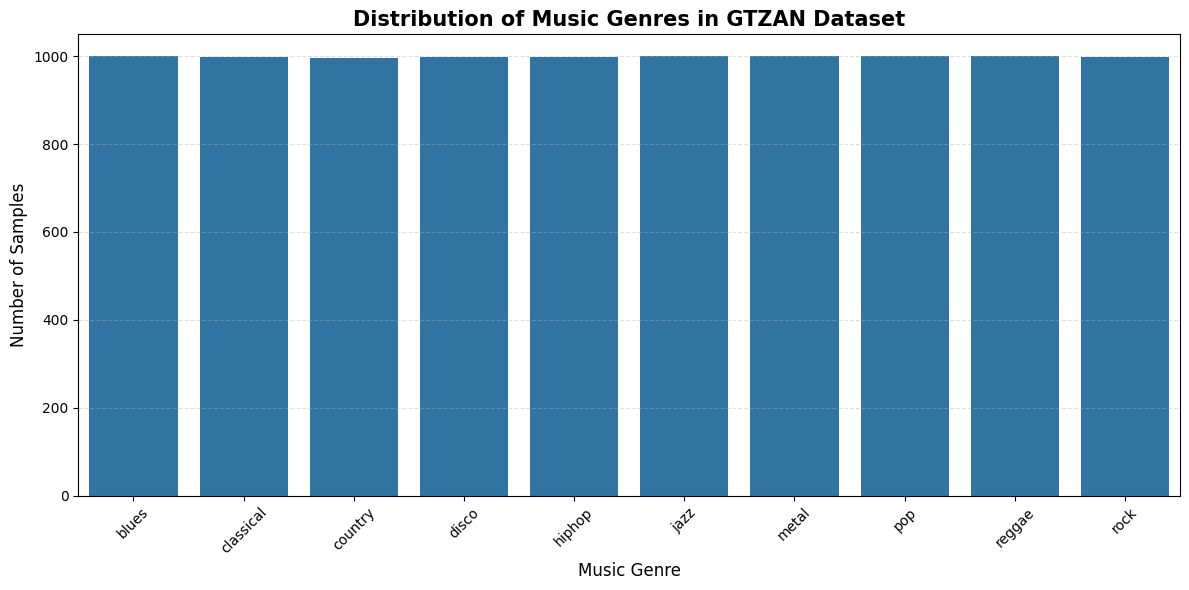

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Calculate genre distribution
genre_counts = df["label"].value_counts().sort_index()

# Create figure
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Distribution of Music Genres in GTZAN Dataset",
          fontsize=15, fontweight="bold")

plt.xlabel("Music Genre", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(project_path, "genre_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

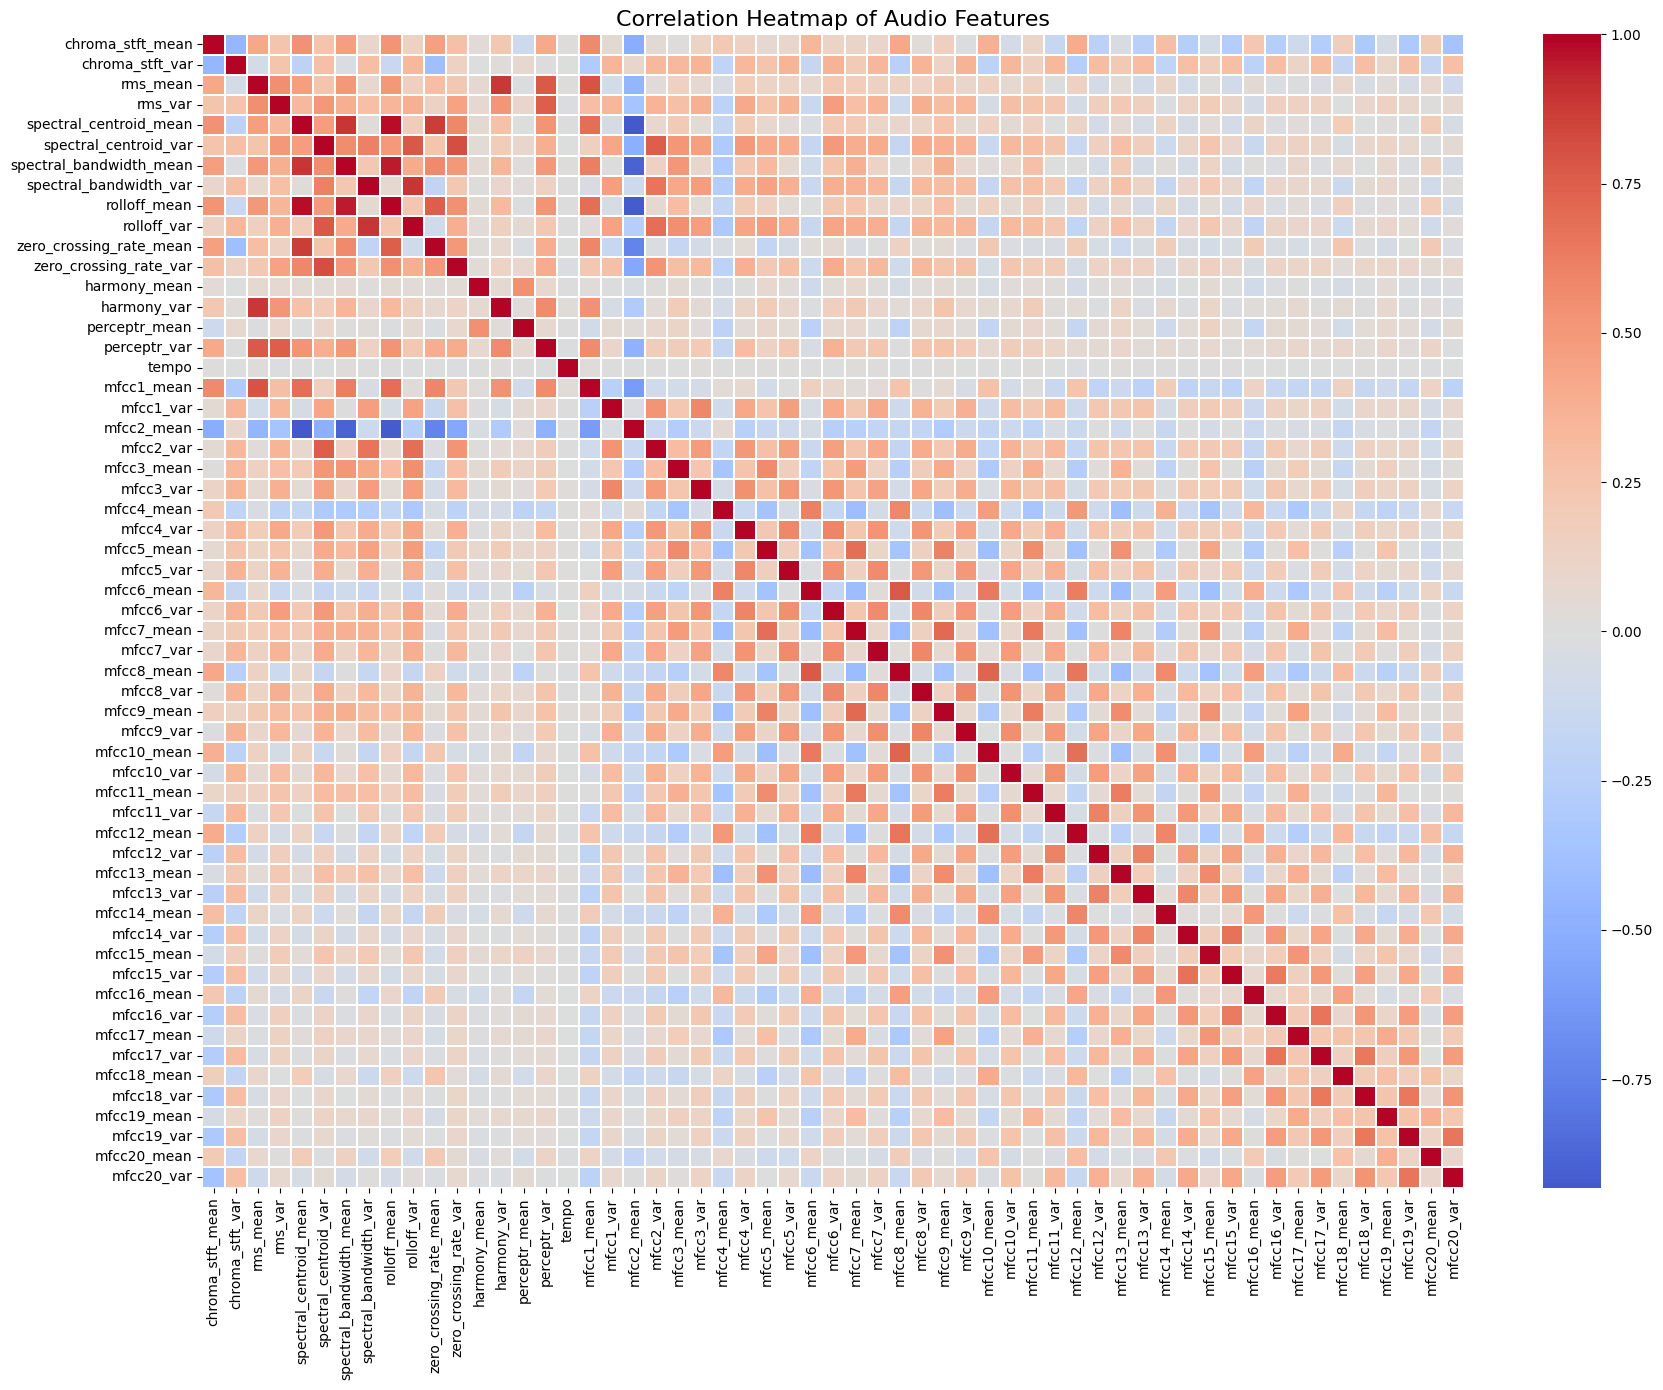

In [66]:
# Audio Feature Correlation Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between numerical audio features
correlation_matrix = X.corr()

# Plot the heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Audio Features", fontsize=16)
plt.tight_layout()
plt.show()

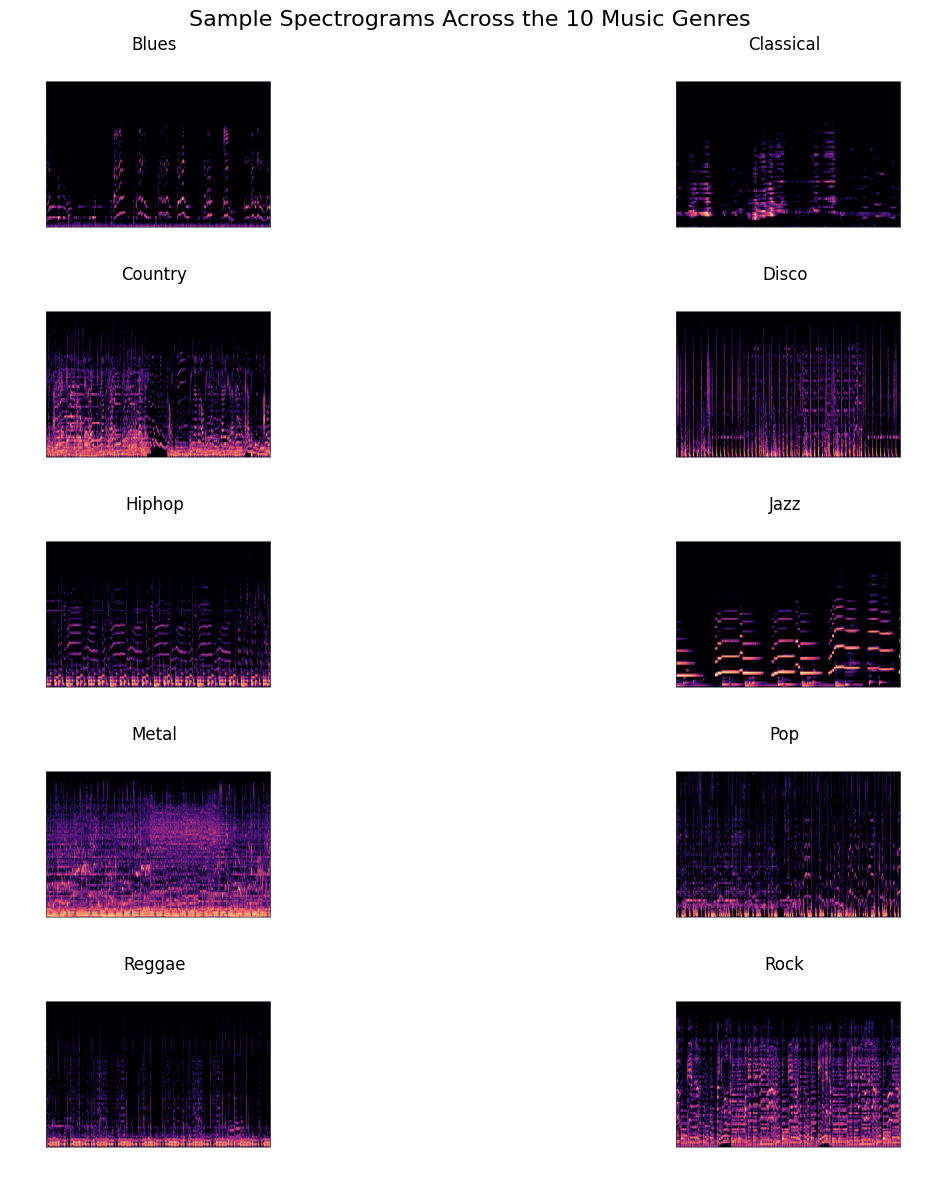

In [67]:
# Display sample spectrograms from different music genres

import matplotlib.pyplot as plt
import os
import random

genres = sorted(image_df["genre"].unique())

plt.figure(figsize=(16, 12))

for i, genre in enumerate(genres):
    sample = image_df[image_df["genre"] == genre].sample(1, random_state=42)

    image_path = sample["image_path"].iloc[0]
    img = plt.imread(image_path)

    plt.subplot(5, 2, i + 1)
    plt.imshow(img)
    plt.title(genre.capitalize())
    plt.axis("off")

plt.suptitle("Sample Spectrograms Across the 10 Music Genres", fontsize=16)
plt.tight_layout()
plt.show()

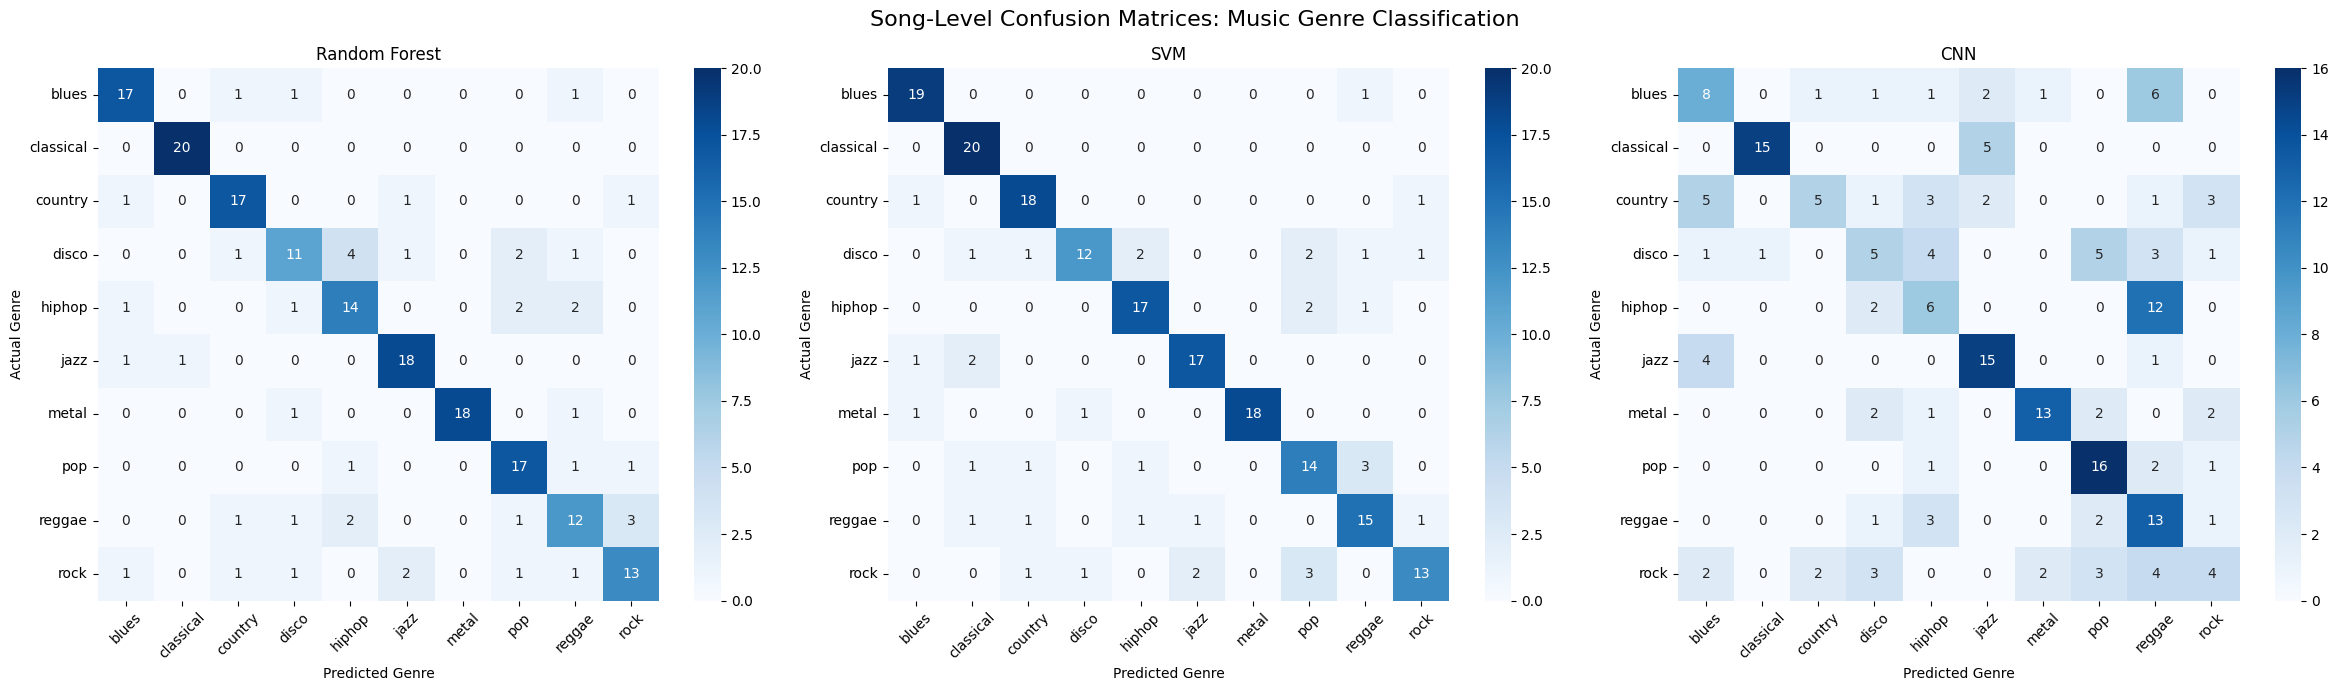

In [68]:
# Confusion Matrices for Random Forest, SVM and CNN

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Consistent genre order
genre_labels = sorted(y.unique())

# Calculate confusion matrices
rf_cm = confusion_matrix(
    rf_song_predictions["actual"],
    rf_song_predictions["predicted"],
    labels=genre_labels
)

svm_cm = confusion_matrix(
    svm_song_predictions["actual"],
    svm_song_predictions["predicted"],
    labels=genre_labels
)

cnn_actual_labels = label_encoder_cnn.inverse_transform(y_cnn_test_encoded)
cnn_predicted_labels = label_encoder_cnn.inverse_transform(cnn_test_predictions)

cnn_cm = confusion_matrix(
    cnn_actual_labels,
    cnn_predicted_labels,
    labels=genre_labels
)

# Plot all three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

matrices = [
    (rf_cm, "Random Forest"),
    (svm_cm, "SVM"),
    (cnn_cm, "CNN")
]

for ax, (matrix, title) in zip(axes, matrices):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=genre_labels,
        yticklabels=genre_labels,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("Actual Genre")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Song-Level Confusion Matrices: Music Genre Classification",
             fontsize=16)

plt.tight_layout()
plt.show()

In [69]:
# Check available CNN training history variables

history_names = [
    name for name in globals()
    if name.startswith("history_batch")
]

print("Available training histories:")

for name in sorted(history_names):
    history = globals()[name]
    print(
        name,
        "| Epochs:", len(history.history["accuracy"])
    )

Available training histories:
history_batch1 | Epochs: 5
history_batch2 | Epochs: 5
history_batch3 | Epochs: 5
history_batch4 | Epochs: 5


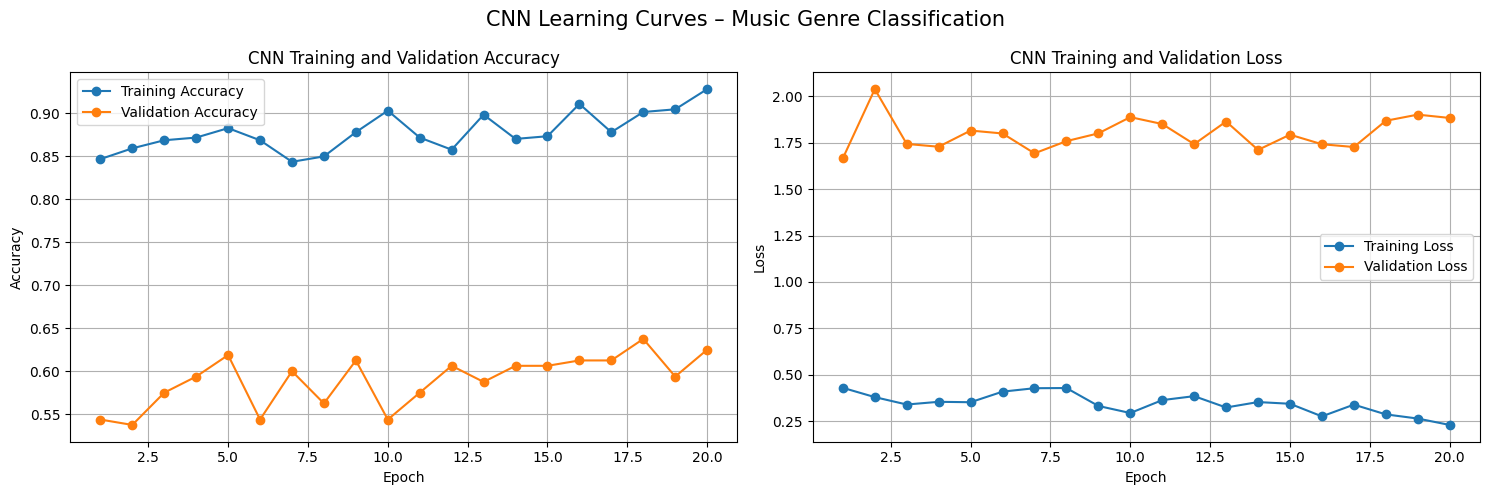

In [70]:
# Combine CNN training histories across all 20 epochs

import matplotlib.pyplot as plt

histories = [
    history_batch1,
    history_batch2,
    history_batch3,
    history_batch4
]

train_accuracy = []
val_accuracy = []
train_loss = []
val_loss = []

for history in histories:
    train_accuracy.extend(history.history["accuracy"])
    val_accuracy.extend(history.history["val_accuracy"])
    train_loss.extend(history.history["loss"])
    val_loss.extend(history.history["val_loss"])

epochs = range(1, len(train_accuracy) + 1)

# Create two learning curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy curve
axes[0].plot(epochs, train_accuracy, marker="o", label="Training Accuracy")
axes[0].plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss curve
axes[1].plot(epochs, train_loss, marker="o", label="Training Loss")
axes[1].plot(epochs, val_loss, marker="o", label="Validation Loss")
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("CNN Learning Curves – Music Genre Classification", fontsize=15)
plt.tight_layout()
plt.show()

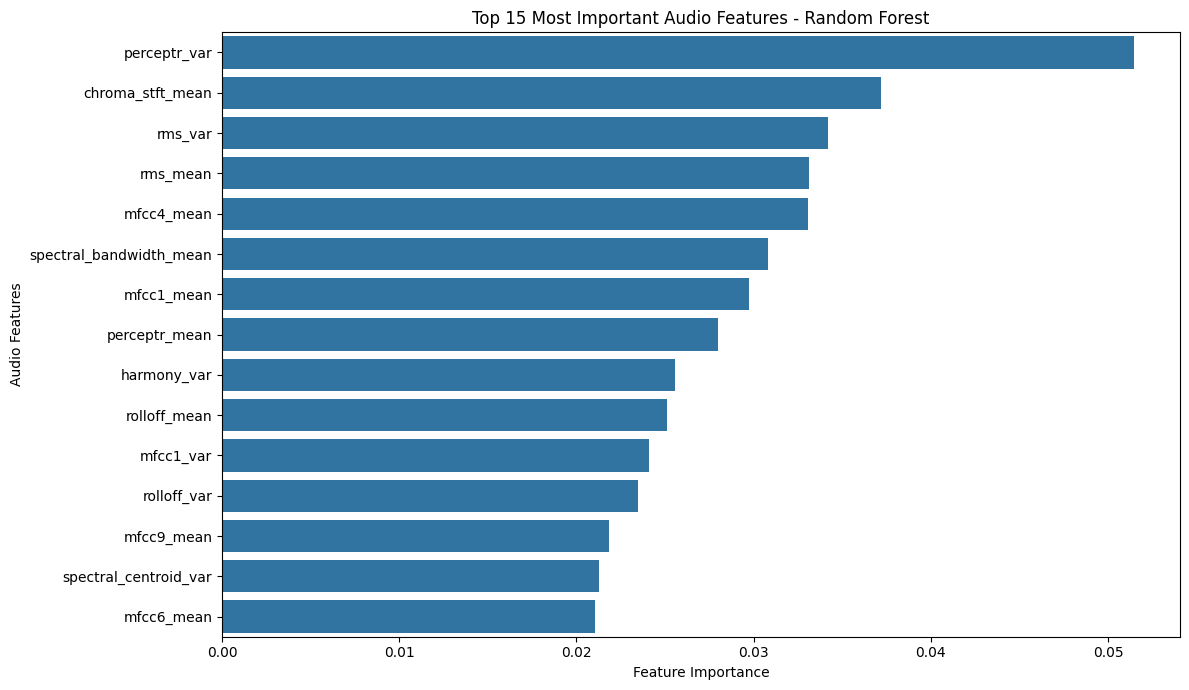

In [71]:
# Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train_grouped.columns,
    "Importance": rf_grouped.feature_importances_
})

# Sort and select the top 15 features
top_features = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Visualise the top features
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important Audio Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Audio Features")
plt.tight_layout()
plt.show()

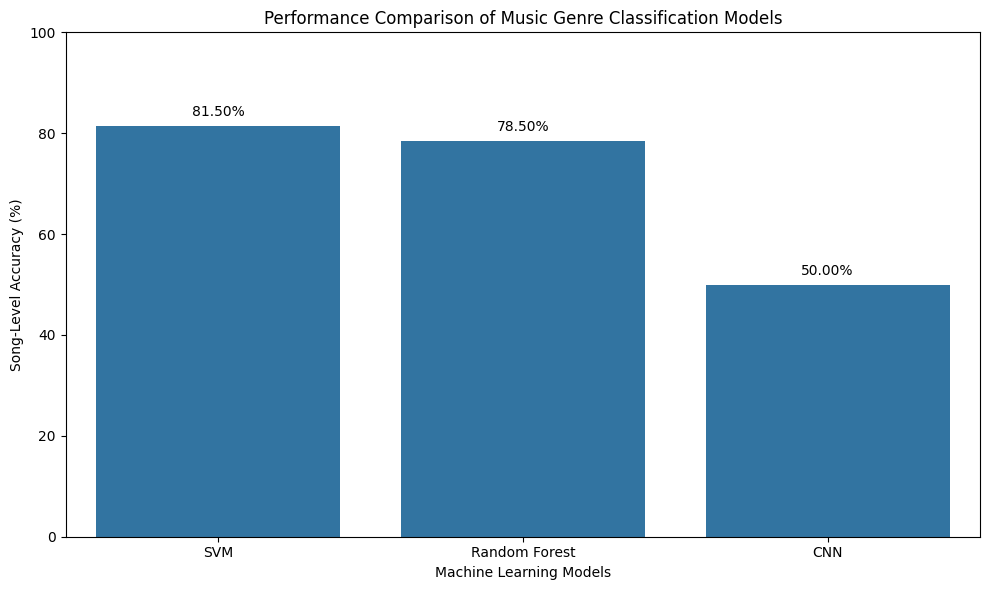

In [72]:
# Compare the performance of all three models

import matplotlib.pyplot as plt
import seaborn as sns

# Display model accuracy comparison
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=complete_results,
    x="Model",
    y="Accuracy_Percentage"
)

# Add accuracy labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Performance Comparison of Music Genre Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Song-Level Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [73]:
# Create a folder for all project visualisations

import os

visualization_path = os.path.join(project_path, "Visualizations")

os.makedirs(visualization_path, exist_ok=True)

print("Visualisations folder created successfully!")
print("Folder location:", visualization_path)

Visualisations folder created successfully!
Folder location: /content/drive/MyDrive/Elevo/Level 3/Task 6/Visualizations


In [74]:
# Save all seven project visualisations

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Confirm output folder
os.makedirs(visualization_path, exist_ok=True)

# 1. Genre distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="label")
plt.title("Distribution of Music Genres in GTZAN Dataset")
plt.xlabel("Music Genre")
plt.ylabel("Number of Audio Segments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "01_genre_distribution.png"), dpi=300)
plt.close()

# 2. Audio feature correlation heatmap
plt.figure(figsize=(18, 14))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, linewidths=0.1)
plt.title("Correlation Heatmap of Audio Features")
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "02_feature_correlation.png"), dpi=300)
plt.close()

# 3. Sample spectrograms
genres = sorted(image_df["genre"].unique())
fig, axes = plt.subplots(5, 2, figsize=(16, 12))

for i, genre in enumerate(genres):
    sample = image_df[image_df["genre"] == genre].sample(1, random_state=42)
    img = plt.imread(sample["image_path"].iloc[0])
    axes[i // 2, i % 2].imshow(img)
    axes[i // 2, i % 2].set_title(genre.capitalize())
    axes[i // 2, i % 2].axis("off")

fig.suptitle("Sample Spectrograms Across the 10 Music Genres", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "03_sample_spectrograms.png"), dpi=300)
plt.close()

# 4. Song-level confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (matrix, title) in zip(
    axes,
    [(rf_cm, "Random Forest"), (svm_cm, "SVM"), (cnn_cm, "CNN")]
):
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues",
        xticklabels=genre_labels, yticklabels=genre_labels, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("Actual Genre")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Song-Level Confusion Matrices: Music Genre Classification")
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "04_confusion_matrices.png"), dpi=300)
plt.close()

# 5. CNN learning curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs = range(1, len(train_accuracy) + 1)

axes[0].plot(epochs, train_accuracy, marker="o", label="Training Accuracy")
axes[0].plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, train_loss, marker="o", label="Training Loss")
axes[1].plot(epochs, val_loss, marker="o", label="Validation Loss")
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

fig.suptitle("CNN Learning Curves – Music Genre Classification")
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "05_cnn_learning_curves.png"), dpi=300)
plt.close()

# 6. Random Forest feature importance
plt.figure(figsize=(12, 7))
sns.barplot(data=top_features, x="Importance", y="Feature")
plt.title("Top 15 Most Important Audio Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Audio Features")
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "06_feature_importance.png"), dpi=300)
plt.close()

# 7. Overall model comparison
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=complete_results, x="Model", y="Accuracy_Percentage")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Performance Comparison of Music Genre Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Song-Level Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(os.path.join(visualization_path, "07_model_comparison.png"), dpi=300)
plt.close()

# Verify saved files
saved_files = os.listdir(visualization_path)

print("Visualisation saving completed!")
print("Total files:", len(saved_files))

for file in sorted(saved_files):
    print("✓", file)

Visualisation saving completed!
Total files: 7
✓ 01_genre_distribution.png
✓ 02_feature_correlation.png
✓ 03_sample_spectrograms.png
✓ 04_confusion_matrices.png
✓ 05_cnn_learning_curves.png
✓ 06_feature_importance.png
✓ 07_model_comparison.png
